In [16]:
import copy
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    Species,
    SpeciesCollection,
    bulk_silicate_earth_abundances,
    debug_logger,
    earth_oceans_to_hydrogen_mass,
)
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
logger.setLevel(logging.DEBUG)

In [89]:
# number_of_realisations = 10000
number_of_realisations = 100
magma_ocean_temperature = 1800
# In the paper we perform simulations at 0.1 and 1.0 melt fraction
mantle_melt_fraction = 0.1

# Venus-like surface temperature
hot_surface_temperature = 740

# Corresponds to the highest temperature at which all condensates can form
medium_surface_temperature = 380

# Corresponds to the equilibrium temperature of Trappist-1e
cold_surface_temperature = 280

# For no particular reason, use 24 as the random seed
RANDOM_SEED = 24
WRITE_OUTPUT = True

# These are just to know at which temperatures condensates are stable
# Temperature must be equal to or less than these values for water condensation and water
# freezing to be applicable.
# water_condensation = 600.0  # First thermo data for H2O(l)

# For naming output data
magma_ocean_temp_str: str = f"{magma_ocean_temperature:0.0f}"
hot_temp_str: str = f"{hot_surface_temperature:0.0f}"
medium_temp_str: str = f"{medium_surface_temperature:0.0f}"
cold_temp_str: str = f"{cold_surface_temperature:0.0f}"

In [90]:
np.random.seed(RANDOM_SEED)
log10_number_oceans = np.random.uniform(-1, 1, number_of_realisations)
log10_ch_ratios = np.random.uniform(-1, 1, number_of_realisations)
fO2_log10_shifts = np.random.uniform(-5, 5, number_of_realisations)

h_kg = earth_oceans_to_hydrogen_mass(10**log10_number_oceans)
c_kg = h_kg * 10**log10_ch_ratios

trappist1e_mantle_mass = 2.912e24
trappist1e_planet_mass = trappist1e_mantle_mass / (1 - 0.295334691460966)
trappist1e_surface_radius = 5.861e6

fugacity_constraints = {"O2_g": IronWustiteBuffer(fO2_log10_shifts)}

In [91]:
solubility_models = get_solubility_models()

H2O_g = Species.create_gas("H2O", solubility=solubility_models["H2O_basalt_dixon95"])
H2_g = Species.create_gas("H2", solubility=solubility_models["H2_basalt_hirschmann12"])
O2_g = Species.create_gas("O2")
CO_g = Species.create_gas("CO", solubility=solubility_models["CO_basalt_yoshioka19"])
CO2_g = Species.create_gas("CO2", solubility=solubility_models["CO2_basalt_dixon95"])
CH4_g = Species.create_gas("CH4", solubility=solubility_models["CH4_basalt_ardia13"])
N2_g = Species.create_gas("N2", solubility=solubility_models["N2_basalt_libourel03"])
H3N_g = Species.create_gas("H3N")
# Graphite can also be present in high temperature atmospheres
C_cr = Species.create_condensed("C")
# Condensates below are used for cooler atmospheres
H2O_l = Species.create_condensed("H2O", state="l")

species_with_all_condensates = SpeciesCollection(
    (
        H2_g,
        H2O_g,
        O2_g,
        CO_g,
        CO2_g,
        CH4_g,
        N2_g,
        H3N_g,
        C_cr,
        H2O_l,
    )
)

In [92]:
trappist1e_magma_ocean = Planet(
    surface_temperature=magma_ocean_temperature,
    planet_mass=trappist1e_planet_mass,
    surface_radius=trappist1e_surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [93]:
earth = Planet(surface_temperature=magma_ocean_temperature)

In [94]:
earth_bse = bulk_silicate_earth_abundances()

In [95]:
trappist1e_bse = copy.deepcopy(earth_bse)
mass_scale_factor = trappist1e_magma_ocean.mantle_mass / earth.mantle_mass

for element, values in trappist1e_bse.items():
    trappist1e_bse[element] = {key: value * mass_scale_factor for key, value in values.items()}  # type: ignore

trappist1e_bse

{'H': {'min': Array(1.281532612814915e+20, dtype=float64),
  'max': Array(1.310595447446787e+21, dtype=float64),
  'mean': Array(7.19374354364139e+20, dtype=float64)},
 'C': {'min': Array(1.222714971298032e+20, dtype=float64),
  'max': Array(2.125738761645474e+21, dtype=float64),
  'mean': Array(1.124005129387639e+21, dtype=float64)},
 'S': {'min': Array(5.823638482424581e+20, dtype=float64),
  'max': Array(7.279548103030726e+20, dtype=float64),
  'mean': Array(6.551593292727653e+20, dtype=float64)},
 'N': {'min': Array(2.417059080217331e+18, dtype=float64),
  'max': Array(7.279548103030726e+18, dtype=float64),
  'mean': Array(4.848303591624028e+18, dtype=float64)},
 'Cl': {'min': Array(5.240997845280866e+19, dtype=float64),
  'max': Array(9.902122942430578e+19, dtype=float64),
  'mean': Array(7.571560393855723e+19, dtype=float64)}}

In [96]:
#normal constraints on mass

mass_constraints = {
    "H": h_kg,
    "C": c_kg,
    "N": trappist1e_bse["N"]["mean"],
}

In [97]:
# Vary Linearly:

log10_H_frac = np.linspace(-1.0, 0.5, number_of_realisations)  # 0.1 to 3% of planet mass

# Fix Values for Linearly Varying Cases:
log10_ch_ratios = np.full(number_of_realisations, -0.5)  # 100X Solar
fO2_log10_shifts = np.full(number_of_realisations, -3)

h_kg = ((10**log10_H_frac) / 100) * trappist1e_planet_mass
c_kg = h_kg * 10**log10_ch_ratios

mass_constraints = {
    "H": h_kg,
    "C": c_kg,
    "N": trappist1e_bse["N"]["mean"],
}

In [113]:
interior_atmosphere_hot = InteriorAtmosphere(species_with_all_condensates)

trappist1e_hot = Planet(
    surface_temperature=medium_surface_temperature,
    planet_mass=trappist1e_planet_mass,
    surface_radius=trappist1e_surface_radius,
    mantle_melt_fraction=0.1,
)

interior_atmosphere_hot.solve(
    planet=trappist1e_hot,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints
)
output_hot = interior_atmosphere_hot.output

if WRITE_OUTPUT:
    # Write the complete solution to Excel
    output_hot.to_excel("FELIXCOND")

    # Write the data to a pickle file with dataframes
    output_hot.to_pickle("FELIXCOND")

[17:58:51 - atmodeller.classes             - INFO     ] - species = ('H2_g: IdealGas, SolubilityPowerLawLog10', 'H2O_g: IdealGas, SolubilityPowerLaw', 'O2_g: IdealGas, NoSolubility', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CH4_g: IdealGas, _CH4_basalt_ardia13', 'N2_g: IdealGas, _N2_basalt_libourel03', 'H3N_g: IdealGas, NoSolubility', 'C_cr: CondensateActivity, NoSolubility', 'H2O_l: CondensateActivity, NoSolubility')
[17:58:51 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 274 K and 600 K
[17:58:51 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2O_g + 1.0 CO_g = 1.0 H2_g + 1.0 CO2_g',
 1: '3.0 H2_g + 1.0 CO_g = 1.0 H2O_g + 1.0 CH4_g',
 2: '2.0 H2O_g = 2.0 H2_g + 1.0 O2_g',
 3: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 4: '1.0 H2_g + 1.0 CO_g = 1.0 H2O_g + 1.0 C_cr',
 5: '1.0 H2O_g = 1.0 H2O_l'}
[17:58:51 - atmodeller.classes             - INFO     ] - Attempting to solve 100 mod

In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

def plot_molecular_budget_from_excels(excel_file, number_of_realisations=100, species=None):
    """
    Plot molecular budget (atmosphere vs dissolved vs condensed)
    for each species from a real-gas Excel output file.
    """

    print("\n" + "="*70)
    print("Creating molecular budget plot from:", excel_file)
    print("="*70)
    
    if species is None:
        species = ['H2O', 'H2_g', 'CH4_g', 'CO2_g', 'CO_g', 'O2_g', 'C_cr']
    
    log10_H_frac = np.linspace(-1.0, 0.5, number_of_realisations)
    H_frac_percent = 10**log10_H_frac * 100

    n_species = len(species)
    ncols = 3
    nrows = math.ceil(n_species / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows))
    axes = np.array(axes).flatten()

    # Small multiplicative margin for log scale (e.g., 1.01 = 1% on each side)
    margin_factor = 1.01
    H_min = H_frac_percent.min() / margin_factor
    H_max = H_frac_percent.max() * margin_factor

    for i, sp in enumerate(species):
        ax = axes[i]

        if sp == 'H2O':
            try:
                df_g = pd.read_excel(excel_file, sheet_name='H2O_g')
                df_l = pd.read_excel(excel_file, sheet_name='H2O_l')
            except Exception:
                print("⚠️ Skipping H2O: missing sheets.")
                continue

            con_mass = df_l['total_mass'].values
            atm_mass = df_g['total_mass'].values
            dis_mass = np.zeros_like(atm_mass)

        else:
            try:
                df = pd.read_excel(excel_file, sheet_name=sp)
            except Exception:
                print(f"⚠️ Skipping {sp}: sheet not found.")
                continue

            if sp == 'C_cr':
                atm_mass = np.zeros(len(df))
                dis_mass = np.zeros(len(df))
                con_mass = df['total_mass'].values
            else:
                atm_mass = df['atmosphere_mass'].values if 'atmosphere_mass' in df.columns else np.zeros(len(df))
                dis_mass = df['dissolved_mass'].values if 'dissolved_mass' in df.columns else np.zeros(len(df))
                con_mass = df['condensed_mass'].values if 'condensed_mass' in df.columns else np.zeros(len(df))

        n = len(H_frac_percent)
        if len(atm_mass) != n:
            x_old = np.linspace(0, 1, len(atm_mass))
            x_new = np.linspace(0, 1, n)
            atm_mass = np.interp(x_new, x_old, atm_mass)
            dis_mass = np.interp(x_new, x_old, dis_mass)
            con_mass = np.interp(x_new, x_old, con_mass)

        total_mass = atm_mass + dis_mass + con_mass
        total_mass[total_mass == 0] = np.nan

        if np.any(atm_mass > 0):
            ax.fill_between(H_frac_percent, 0, atm_mass/total_mass*100, 
                            label='Atmosphere', color='#1f77b4', alpha=0.7)
        if np.any(dis_mass > 0):
            ax.fill_between(H_frac_percent, atm_mass/total_mass*100, 
                            (atm_mass+dis_mass)/total_mass*100, 
                            label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.any(con_mass > 0):
            ax.fill_between(H_frac_percent, (atm_mass+dis_mass)/total_mass*100, 100, 
                            label='Condensed', color='#2ca02c', alpha=0.7)

        ax.set_xscale('log')
        ax.set_xlim(H_min, H_max)
        ax.set_ylim(0, 100)
        ax.set_xlabel("H Mass Fraction (% of planet mass)")
        ax.set_ylabel("Distribution (%)")
        ax.set_title(f"({chr(97+i)}) {sp.replace('_g','').upper()} Budget", fontweight='bold')
        ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)

        # Legend in lower-left, inside plot area
        ax.legend(loc='lower left', frameon=True, fontsize=9)

    for j in range(len(species), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.savefig("sub_neptune_molecular_budget.png", dpi=300, bbox_inches='tight')
    print("\n✓ Successfully saved: sub_neptune_molecular_budget.png")
    print("="*70)
    plt.show()



Creating molecular budget plot from: FELIXCOND.xlsx

✓ Successfully saved: sub_neptune_molecular_budget.png


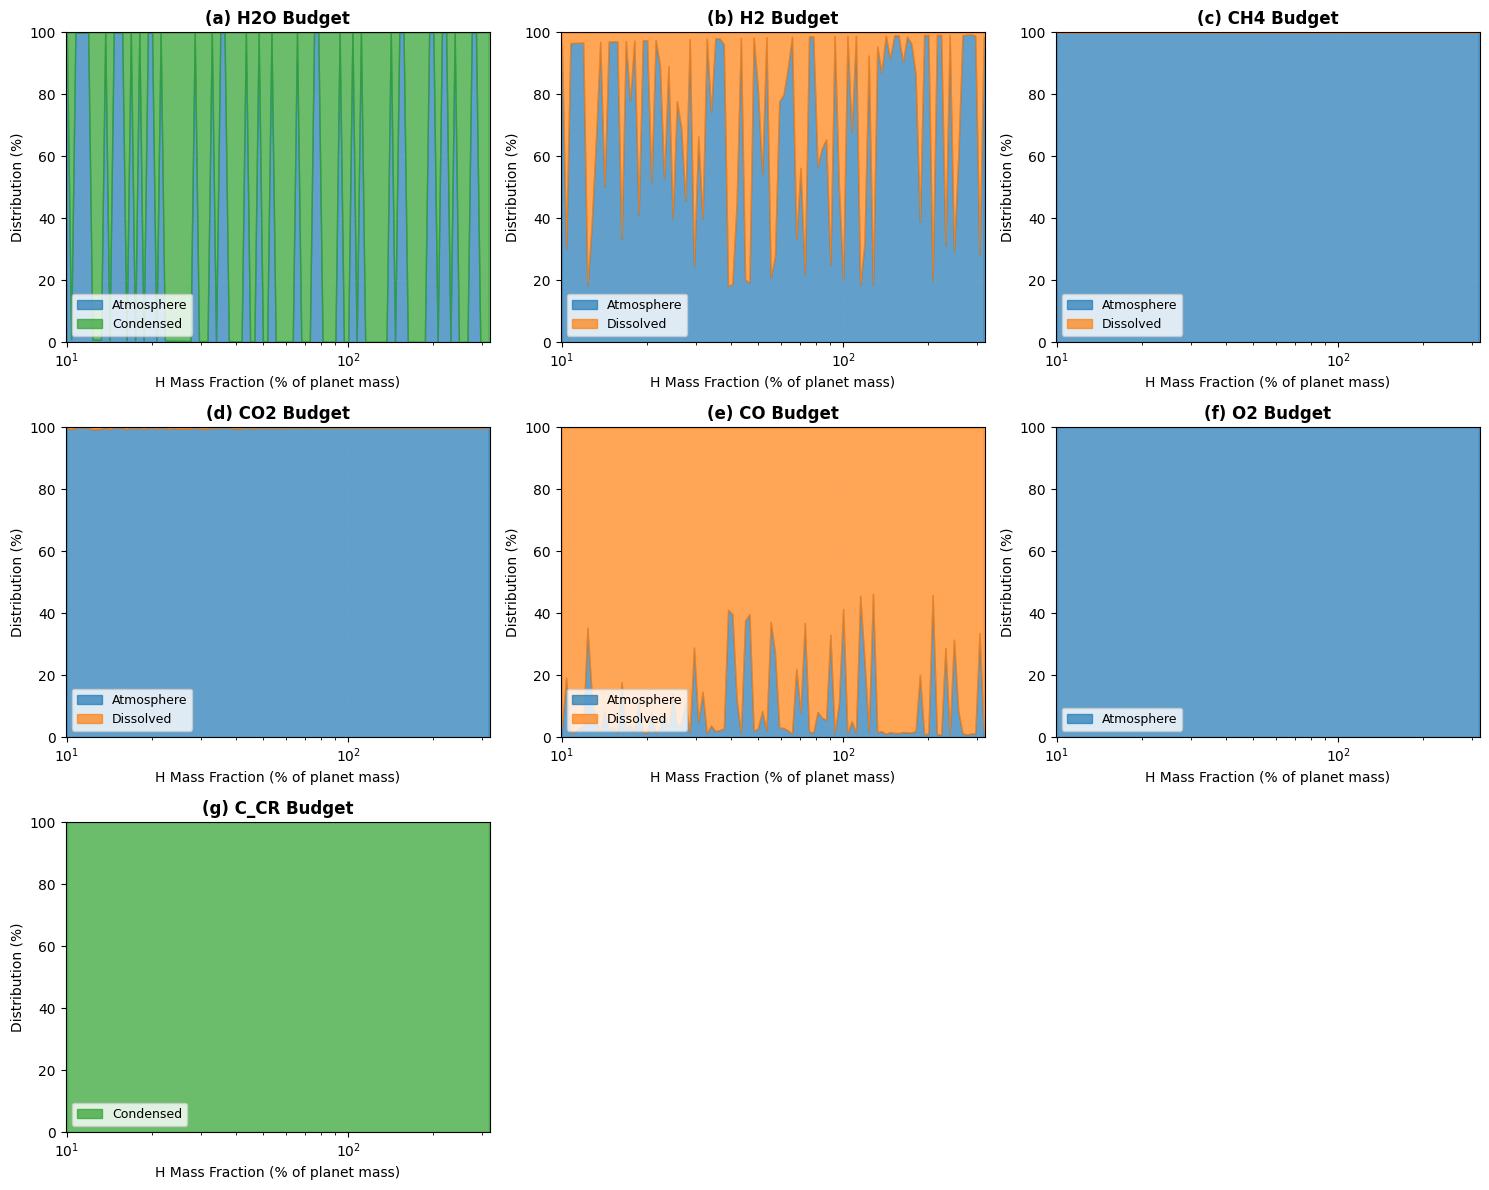

In [115]:
plot_molecular_budget_from_excels("FELIXCOND.xlsx")

In [118]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_elemental_budget_from_excel(excel_file, elements=('C','H','O','N')):
    print("\n" + "="*70)
    print("Creating elemental budget plot from Excel...")
    print("="*70)

    df_H = pd.read_excel(excel_file, sheet_name='element_H')
    if 'atmosphere_ppmw' not in df_H.columns:
        raise KeyError("Could not find atmosphere_ppmw in element_H sheet.")

    H_frac_percent = df_H['atmosphere_ppmw'] / 1e4  # ppmw → %

    fig, axes = plt.subplots(1, len(elements), figsize=(16, 5))

    for idx, element in enumerate(elements):
        ax = axes[idx]
        sheet = f'element_{element}'
        df = pd.read_excel(excel_file, sheet_name=sheet)

        # Use .get() with fallback to zeros
        atm_mass = df.get('atmosphere_mass', pd.Series(np.zeros(len(df))))
        dis_mass = df.get('dissolved_mass', pd.Series(np.zeros(len(df))))
        con_mass = df.get('condensed_mass', pd.Series(np.zeros(len(df))))

        total_mass = atm_mass + dis_mass + con_mass
        total_mass[total_mass == 0] = np.nan  # avoid divide by zero

        atm_frac = atm_mass / total_mass * 100
        dis_frac = dis_mass / total_mass * 100
        con_frac = con_mass / total_mass * 100

        # Compute cumulative stacked boundaries
        y1 = atm_frac
        y2 = atm_frac + dis_frac
        y3 = atm_frac + dis_frac + con_frac

        # Clip to [0, 100] so nothing spills out of the plot
        y1, y2, y3 = [np.clip(y, 0, 100) for y in (y1, y2, y3)]

        # Plot stacked areas
        ax.fill_between(H_frac_percent, 0, y1, label='Atmosphere', color='#1f77b4', alpha=0.7)
        ax.fill_between(H_frac_percent, y1, y2, label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.nanmax(con_frac) > 0:
            ax.fill_between(H_frac_percent, y2, y3, label='Condensed', color='#2ca02c', alpha=0.7)

        ax.set_xscale('log')
        ax.set_ylim(0, 100)
        ax.set_xlabel('H Mass Fraction (%)')
        ax.set_ylabel(f'{element} Distribution (%)')
        ax.set_title(f'({chr(97+idx)}) {element} Budget', fontweight='bold')
        ax.legend(loc='best', frameon=True, fontsize=9)
        ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)

    plt.tight_layout()
    plt.savefig('sub_neptune_elemental_budget_from_excel.png', dpi=300, bbox_inches='tight')
    print("\n✓ Successfully saved: sub_neptune_elemental_budget_from_excel.png")
    plt.show()



Creating elemental budget plot from Excel...

✓ Successfully saved: sub_neptune_elemental_budget_from_excel.png


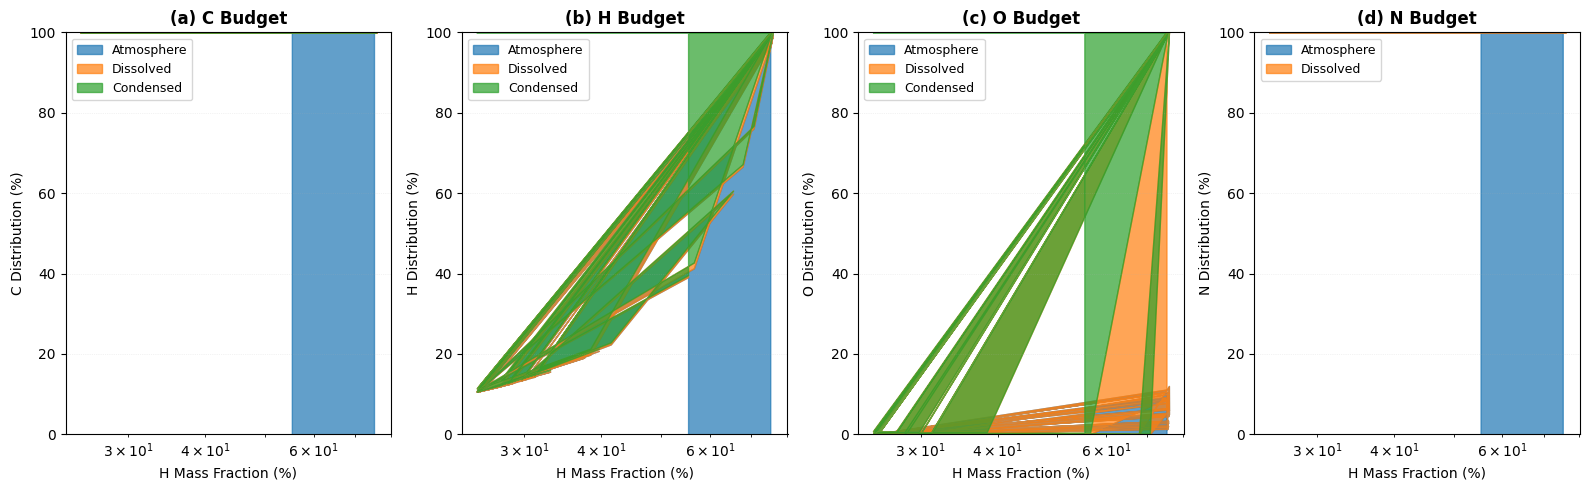

In [119]:
plot_elemental_budget_from_excel("FELIXCOND.xlsx")
